In [1]:
import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score, average_precision_score, confusion_matrix, precision_score, recall_score, f1_score, accuracy_score, fbeta_score
import re
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display, HTML
import itertools
import warnings
warnings.filterwarnings('ignore')

In [2]:
data_gpt = pd.read_csv('../data/llm_data/gpt.csv', index_col=[0])
data_alpaca = pd.read_csv('../data/llm_data/alpaca.csv', index_col=[0])
data_vicuna = pd.read_csv('../data/llm_data/vicuna.csv', index_col=[0])
data_mistral = pd.read_csv('../data/llm_data/mistral.csv', index_col=[0])
data_flan = pd.read_csv('../data/llm_data/flan_t5.csv', index_col=[0])
data_gemini = pd.read_csv('../data/llm_data/gemini.csv', index_col=[0])

In [8]:
# View one of the data to undertstand the structure

data_gpt

,uniqueID,trigger_event,label,roleplay,content,zero-shot,few-shot
0,poli_ukdata_24-0,political,1,sexist,sexist,sexist,sexist
1,poli_ukdata_24-1,political,0,sexist,sexist,sexist,sexist
2,poli_ukdata_24-2,political,0,not sexist,not sexist,not sexist,not sexist
3,poli_ukdata_24-3,political,0,sexist,not sexist,sexist,sexist
4,poli_ukdata_24-4,political,0,not sexist,not sexist,not sexist,not sexist
...,...,...,...,...,...,...,...
1268,poli_ukdata_24-1268,political,0,sexist,not sexist,sexist,not sexist
1269,poli_ukdata_24-1269,political,0,sexist,sexist,sexist,not sexist
1270,poli_ukdata_24-1270,political,0,sexist,not sexist,sexist,sexist
1271,poli_ukdata_24-1271,political,0,not sexist,not sexist,not sexist,not sexist


In [9]:
# Actual metadata # need not be taken from this dataset
data = pd.read_csv('../data/sexist_political_metadata.csv')

In [10]:
data_labels = data[['trigger_event', 'label']]
data_labels = data_labels.groupby('trigger_event')['label'].value_counts().reset_index()
data_labels['percentage'] = round(100 * data_labels['count'] / data_labels.groupby('trigger_event')['count'].transform('sum'), 2)
data_labels = data_labels.sort_values(by='trigger_event')
data_labels

,trigger_event,label,count,percentage
0,political,0,539,95.23
1,political,1,27,4.77
2,sexist,0,624,88.26
3,sexist,1,83,11.74


In [11]:
def replace_items(text):
    #text = text.astype(str)
    text = text.lower().strip()

    punc = '''!()-[]{};:'"\,<>./?@#$%^&*_~'''

    for ele in text:
        if ele in punc:
            text = text.replace(ele, "")
    #text = text.replace('not sexist', 0)
    #text = text.replace('sexist', 1)
    return text

In [12]:
data_gpt['roleplay'] = data_gpt['roleplay'].apply(lambda x: replace_items(x))
data_gpt['content'] = data_gpt['content'].apply(lambda x: replace_items(x))
data_gpt['zero-shot'] = data_gpt['zero-shot'].apply(lambda x: replace_items(x))
data_gpt['few-shot'] = data_gpt['few-shot'].apply(lambda x: replace_items(x))
data_gpt[['roleplay', 'content', 'zero-shot', 'few-shot']] = data_gpt[['roleplay', 'content', 'zero-shot', 'few-shot']].replace({'not sexist': 0, 'sexist': 1})

data_alpaca['roleplay'] = data_alpaca['roleplay'].apply(lambda x: replace_items(x))
data_alpaca['content'] = data_alpaca['content'].apply(lambda x: replace_items(x))
data_alpaca['zero-shot'] = data_alpaca['zero-shot'].apply(lambda x: replace_items(x))
data_alpaca['few-shot'] = data_alpaca['few-shot'].apply(lambda x: replace_items(x))
data_alpaca[['roleplay', 'content', 'zero-shot', 'few-shot']] = data_alpaca[['roleplay', 'content', 'zero-shot', 'few-shot']].replace({'not sexist': 0, 'sexist': 1})

data_flan['roleplay'] = data_flan['roleplay'].apply(lambda x: replace_items(x))
data_flan['content'] = data_flan['content'].apply(lambda x: replace_items(x))
data_flan['zero-shot'] = data_flan['zero-shot'].apply(lambda x: replace_items(x))
data_flan['few-shot'] = data_flan['few-shot'].apply(lambda x: replace_items(x))
data_flan[['roleplay', 'content', 'zero-shot', 'few-shot']] = data_flan[['roleplay', 'content', 'zero-shot', 'few-shot']].replace({'not sexist': 0, 'sexist': 1})

data_vicuna['roleplay'] = data_vicuna['roleplay'].apply(lambda x: replace_items(x))
data_vicuna['content'] = data_vicuna['content'].apply(lambda x: replace_items(x))
data_vicuna['zero-shot'] = data_vicuna['zero-shot'].apply(lambda x: replace_items(x))
data_vicuna['few-shot'] = data_vicuna['few-shot'].apply(lambda x: replace_items(x))
data_vicuna[['roleplay', 'content', 'zero-shot', 'few-shot']] = data_vicuna[['roleplay', 'content', 'zero-shot', 'few-shot']].replace({'not sexist': 0, 'sexist': 1})

data_mistral['roleplay'] = data_mistral['roleplay'].apply(lambda x: replace_items(x))
data_mistral['content'] = data_mistral['content'].apply(lambda x: replace_items(x))
data_mistral['zero-shot'] = data_mistral['zero-shot'].apply(lambda x: replace_items(x))
data_mistral['few-shot'] = data_mistral['few-shot'].apply(lambda x: replace_items(x))
data_mistral[['roleplay', 'content', 'zero-shot', 'few-shot']] = data_mistral[['roleplay', 'content', 'zero-shot', 'few-shot']].replace({'not sexist': 0, 'sexist': 1})

### Chat-GPT

In [180]:
y_n_gpt, pred_n_gpt = data_gpt['label'], data_gpt['roleplay']
y_o_gpt, pred_o_gpt = data_gpt['label'], data_gpt['content']
y_z_gpt, pred_z_gpt = data_gpt['label'], data_gpt['zero-shot']
y_f_gpt, pred_f_gpt = data_gpt['label'], data_gpt['few-shot']

score_table_gpt = pd.DataFrame(columns=['prompt type', 'F1 score', 'Precision', 'Recall', 'Accuracy'])
score_table_gpt['prompt type'] = ['Roleplay', 'Content', 'Zero-shot', 'Few-shot']

f1_n_gpt = f1_score(y_true = y_n_gpt, y_pred= pred_n_gpt, average='macro')
f1_o_gpt = f1_score(y_true = y_o_gpt, y_pred= pred_o_gpt, average='macro')
f1_z_gpt = f1_score(y_true = y_z_gpt, y_pred= pred_z_gpt, average='macro')
f1_f_gpt = f1_score(y_true = y_f_gpt, y_pred= pred_f_gpt, average='macro')

f1_scores_gpt = [f1_n_gpt, f1_o_gpt, f1_z_gpt, f1_f_gpt]
score_table_gpt['F1 score'] = f1_scores_gpt

precision_n_gpt = precision_score(y_true = y_n_gpt, y_pred= pred_n_gpt, average='macro')
precision_o_gpt = precision_score(y_true = y_o_gpt, y_pred= pred_o_gpt, average='macro')
precision_z_gpt = precision_score(y_true = y_z_gpt, y_pred= pred_z_gpt, average='macro')
precision_f_gpt = precision_score(y_true = y_f_gpt, y_pred= pred_f_gpt, average='macro')

precision_scores_gpt = [precision_n_gpt, precision_o_gpt, precision_z_gpt, precision_f_gpt]
score_table_gpt['Precision'] = precision_scores_gpt


recall_n_gpt = recall_score(y_true = y_n_gpt, y_pred= pred_n_gpt, average='macro')
recall_o_gpt = recall_score(y_true = y_o_gpt, y_pred= pred_o_gpt, average='macro')
recall_z_gpt = recall_score(y_true = y_z_gpt, y_pred= pred_z_gpt, average='macro')
recall_f_gpt = recall_score(y_true = y_f_gpt, y_pred= pred_f_gpt, average='macro')

recall_scores_gpt = [recall_n_gpt, recall_o_gpt, recall_z_gpt, recall_f_gpt]
score_table_gpt['Recall'] = recall_scores_gpt

acc_n_gpt = accuracy_score(y_true = y_n_gpt, y_pred= pred_n_gpt)
acc_o_gpt = accuracy_score(y_true = y_o_gpt, y_pred= pred_o_gpt)
acc_z_gpt = accuracy_score(y_true = y_z_gpt, y_pred= pred_z_gpt)
acc_f_gpt = accuracy_score(y_true = y_f_gpt, y_pred= pred_f_gpt)

accuracy_scores_gpt = [acc_n_gpt, acc_o_gpt, acc_z_gpt, acc_f_gpt]
score_table_gpt['Accuracy'] = accuracy_scores_gpt

score_table_gpt[['F1 score', 'Precision', 'Recall', 'Accuracy']] = round(score_table_gpt[['F1 score', 'Precision', 'Recall', 'Accuracy']] * 100, 2)
score_table_gpt

,prompt type,F1 score,Precision,Recall,Accuracy
0,Roleplay,44.36,54.68,64.78,52.95
1,Content,57.91,58.02,70.04,75.33
2,Zero-shot,51.97,56.14,68.37,65.51
3,Few-shot,55.25,57.88,72.86,69.21


In [236]:
# roleplay
gpt_r = data_gpt[['trigger_event', 'roleplay']]
gpt_r = gpt_r.groupby('trigger_event')['roleplay'].value_counts().reset_index()
gpt_r['percentage'] = round(100 * gpt_r['count'] / gpt_r.groupby('trigger_event')['count'].transform('sum'), 2)
gpt_r = gpt_r.sort_values(by='trigger_event')

gpt_r_1 = gpt_r[gpt_r['roleplay'] == 1]['percentage'].to_list()
gpt_r_0 = gpt_r[gpt_r['roleplay'] == 0]['percentage'].to_list()

gpt_r_bylabel = gpt_r.sort_values(by='roleplay')

percent_list_gpt_r = gpt_r_bylabel['percentage'].to_list()
percent_list_gpt_r_1 = gpt_r_bylabel[gpt_r_bylabel['roleplay'] == 1]['percentage'].to_list()
percent_list_gpt_r_0 = gpt_r_bylabel[gpt_r_bylabel['roleplay'] == 0]['percentage'].to_list()

# content
gpt_c = data_gpt[['trigger_event', 'content']]
gpt_c = gpt_c.groupby('trigger_event')['content'].value_counts().reset_index()
gpt_c['percentage'] = round(100 * gpt_c['count'] / gpt_c.groupby('trigger_event')['count'].transform('sum'), 2)
gpt_c = gpt_c.sort_values(by='trigger_event')

gpt_c_1 = gpt_c[gpt_c['content'] == 1]['percentage'].to_list()
gpt_c_0 = gpt_c[gpt_c['content'] == 0]['percentage'].to_list()

gpt_c_bylabel = gpt_c.sort_values(by='content')

percent_list_gpt_c = gpt_c_bylabel['percentage'].to_list()
percent_list_gpt_c_1 = gpt_c_bylabel[gpt_c_bylabel['content'] == 1]['percentage'].to_list()
percent_list_gpt_c_0 = gpt_c_bylabel[gpt_c_bylabel['content'] == 0]['percentage'].to_list()


# zero-shot
gpt_z = data_gpt[['trigger_event', 'zero-shot']]
gpt_z = gpt_z.groupby('trigger_event')['zero-shot'].value_counts().reset_index()
gpt_z['percentage'] = round(100 * gpt_z['count'] / gpt_z.groupby('trigger_event')['count'].transform('sum'), 2)
gpt_z = gpt_z.sort_values(by='trigger_event')

gpt_z_1 = gpt_z[gpt_z['zero-shot'] == 1]['percentage'].to_list()
gpt_z_0 = gpt_z[gpt_z['zero-shot'] == 0]['percentage'].to_list()

gpt_z_bylabel = gpt_z.sort_values(by='zero-shot')

percent_list_gpt_z = gpt_z_bylabel['percentage'].to_list()
percent_list_gpt_z_1 = gpt_z_bylabel[gpt_z_bylabel['zero-shot'] == 1]['percentage'].to_list()
percent_list_gpt_z_0 = gpt_z_bylabel[gpt_z_bylabel['zero-shot'] == 0]['percentage'].to_list()


# few-shot
gpt_f = data_gpt[['trigger_event', 'few-shot']]
gpt_f = gpt_f.groupby('trigger_event')['few-shot'].value_counts().reset_index()
gpt_f['percentage'] = round(100 * gpt_f['count'] / gpt_f.groupby('trigger_event')['count'].transform('sum'), 2)
gpt_f = gpt_f.sort_values(by='trigger_event')

gpt_f_1 = gpt_f[gpt_f['few-shot'] == 1]['percentage'].to_list()
gpt_f_0 = gpt_f[gpt_f['few-shot'] == 0]['percentage'].to_list()

gpt_f_bylabel = gpt_f.sort_values(by='few-shot')

percent_list_gpt_f = gpt_f_bylabel['percentage'].to_list()
percent_list_gpt_f_1 = gpt_f_bylabel[gpt_f_bylabel['few-shot'] == 1]['percentage'].to_list()
percent_list_gpt_f_0 = gpt_f_bylabel[gpt_f_bylabel['few-shot'] == 0]['percentage'].to_list()

percent_list_gpt_1 = [percent_list_gpt_r_1, percent_list_gpt_c_1, percent_list_gpt_z_1, percent_list_gpt_f_1]
percent_list_gpt_1 = list(itertools.chain.from_iterable(percent_list_gpt_1))

In [237]:
## roleplay
gpt_cor_r = data_gpt[['trigger_event', 'label', 'roleplay']].value_counts().reset_index()
gpt_cor_r['percentage'] = round(100 * gpt_cor_r['count'] / gpt_cor_r['count'].sum(), 2)
gpt_cor_r = gpt_cor_r.sort_values(by='trigger_event')

gpt_cor_r_1 = gpt_cor_r[(gpt_cor_r['label'] == 1) & (gpt_cor_r['roleplay'] == 1)]
percent_list_gpt_cor_r_1 = gpt_cor_r_1['percentage'].to_list()
gpt_cor_r_0 = gpt_cor_r[(gpt_cor_r['label'] == 0) & (gpt_cor_r['roleplay'] == 0)]
percent_list_gpt_cor_r_0 = gpt_cor_r_0['percentage'].to_list()

# content
gpt_cor_c = data_gpt[['trigger_event', 'label', 'content']].value_counts().reset_index()
gpt_cor_c['percentage'] = round(100 * gpt_cor_c['count'] / gpt_cor_c['count'].sum(), 2)
gpt_cor_c = gpt_cor_c.sort_values(by='trigger_event')

gpt_cor_c_1 = gpt_cor_c[(gpt_cor_c['label'] == 1) & (gpt_cor_c['content'] == 1)]
percent_list_gpt_cor_c_1 = gpt_cor_c_1['percentage'].to_list()
gpt_cor_c_0 = gpt_cor_c[(gpt_cor_c['label'] == 0) & (gpt_cor_c['content'] == 0)]
percent_list_gpt_cor_c_0 = gpt_cor_c_0['percentage'].to_list()

# zero-shot
gpt_cor_z = data_gpt[['trigger_event', 'label', 'zero-shot']].value_counts().reset_index()
gpt_cor_z['percentage'] = round(100 * gpt_cor_z['count'] / gpt_cor_z['count'].sum(), 2)
gpt_cor_z = gpt_cor_z.sort_values(by='trigger_event')

gpt_cor_z_1 = gpt_cor_z[(gpt_cor_z['label'] == 1) & (gpt_cor_z['zero-shot'] == 1)]
percent_list_gpt_cor_z_1 = gpt_cor_z_1['percentage'].to_list()
gpt_cor_z_0 = gpt_cor_z[(gpt_cor_z['label'] == 0) & (gpt_cor_z['zero-shot'] == 0)]
percent_list_gpt_cor_z_0 = gpt_cor_z_0['percentage'].to_list()

# few-shot
gpt_cor_f = data_gpt[['trigger_event', 'label', 'few-shot']].value_counts().reset_index()
gpt_cor_f['percentage'] = round(100 * gpt_cor_f['count'] / gpt_cor_f['count'].sum(), 2)
gpt_cor_f = gpt_cor_f.sort_values(by='trigger_event')

gpt_cor_f_1 = gpt_cor_f[(gpt_cor_f['label'] == 1) & (gpt_cor_f['few-shot'] == 1)]
percent_list_gpt_cor_f_1 = gpt_cor_f_1['percentage'].to_list()
gpt_cor_f_0 = gpt_cor_f[(gpt_cor_f['label'] == 0) & (gpt_cor_f['few-shot'] == 0)]
percent_list_gpt_cor_f_0 = gpt_cor_f_0['percentage'].to_list()

percent_list_gpt_cor_1 = [percent_list_gpt_cor_r_1, percent_list_gpt_cor_c_1, percent_list_gpt_cor_z_1, percent_list_gpt_cor_f_1]
percent_list_gpt_cor_1 = list(itertools.chain.from_iterable(percent_list_gpt_cor_1))

percent_list_gpt_cor_0 = [percent_list_gpt_cor_r_0, percent_list_gpt_cor_c_0, percent_list_gpt_cor_z_0, percent_list_gpt_cor_f_0]
percent_list_gpt_cor_0 = list(itertools.chain.from_iterable(percent_list_gpt_cor_0))

In [238]:
percent_list_gpt_cor_r_1

[1.73, 5.11]

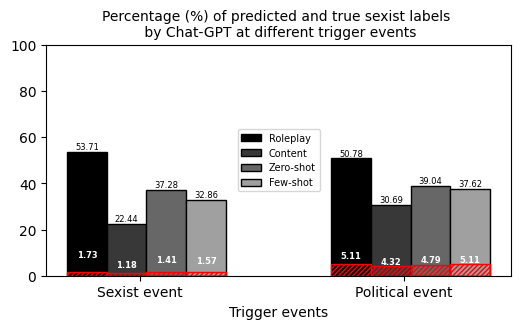

In [370]:
list_events = list(data_gpt['trigger_event'].unique())
X_axis = np.arange(len(list_events)) 

fig, ax = plt.subplots(figsize=(6, 3))

#ax.bar(X_axis - 0.2, data_labels_label_neither, 0.2, label = 'Neither') 
ax.bar(X_axis - 0.20, percent_list_gpt_r_1, 0.15, label = 'Roleplay', color='#000000', edgecolor='black') 
ax.bar(X_axis - 0.05, percent_list_gpt_c_1, 0.15, label = 'Content', color='#383838', edgecolor='black') 
ax.bar(X_axis + 0.10, percent_list_gpt_z_1, 0.15, label = 'Zero-shot', color='#676767', edgecolor='black') 
ax.bar(X_axis + 0.25, percent_list_gpt_f_1, 0.15, label = 'Few-shot', color='#a0a0a0', edgecolor='black') 


ax.bar(X_axis - 0.20 , percent_list_gpt_cor_r_1, 0.15, label = None, color='none', edgecolor='red', hatch = '///////') 
ax.bar(X_axis - 0.05, percent_list_gpt_cor_c_1, 0.15, label = None, color='none', edgecolor='red', hatch = '///////') 
ax.bar(X_axis + 0.10 , percent_list_gpt_cor_z_1, 0.15, label = None, color='none', edgecolor='red', hatch = '///////') 
ax.bar(X_axis + 0.25 , percent_list_gpt_cor_f_1, 0.15, label = None, color='none', edgecolor='red', hatch = '///////') 

plt.xticks(X_axis, ['Sexist event', 'Political event',]) 
ax.set_xlabel("Trigger events") 
ax.set_ylabel("") 
ax.set_title("Percentage (%) of predicted and true sexist labels \n by Chat-GPT at different trigger events", fontdict={'fontsize': 10}) 

rects = ax.patches

# Make some labels.
labels_sexism = [f"{i}" for i in percent_list_gpt_1]
labels_correct_sexism = [f"{i}" for i in percent_list_gpt_cor_1]

for rect, label1, label2 in zip(rects, labels_sexism, labels_correct_sexism):
    height = rect.get_height()
    ax.text(
        rect.get_x() + rect.get_width() / 2, height + 0.3, label1, ha="center", va="bottom", fontsize=6
    )
    ax.text(
        rect.get_x() + rect.get_width() / 2, height / 7.5, label2, ha="center", va="bottom", fontsize=6, weight = 'bold', color = 'white'
    )


plt.ylim([0, 100])
plt.legend(fontsize=7, loc='center') 
plt.show() 

fig.savefig("../images/gpt-correct-sexism.pdf", bbox_inches='tight')

### Alpaca

In [190]:
y_n_alp, pred_n_alp = data_alpaca['label'], data_alpaca['roleplay']
y_o_alp, pred_o_alp = data_alpaca['label'], data_alpaca['content']
y_z_alp, pred_z_alp = data_alpaca['label'], data_alpaca['zero-shot']
y_f_alp, pred_f_alp = data_alpaca['label'], data_alpaca['few-shot']

score_table_alp = pd.DataFrame(columns=['prompt type', 'F1 score', 'Precision', 'Recall', 'Accuracy'])
score_table_alp['prompt type'] = ['Roleplay', 'Content', 'Zero-shot', 'Few-shot']

f1_n_alp = f1_score(y_true = y_n_alp, y_pred= pred_n_alp, average='macro')
f1_o_alp = f1_score(y_true = y_o_alp, y_pred= pred_o_alp, average='macro')
f1_z_alp = f1_score(y_true = y_z_alp, y_pred= pred_z_alp, average='macro')
f1_f_alp = f1_score(y_true = y_f_alp, y_pred= pred_f_alp, average='macro')

f1_scores_alp = [f1_n_alp, f1_o_alp, f1_z_alp, f1_f_alp]
score_table_alp['F1 score'] = f1_scores_alp

precision_n_alp = precision_score(y_true = y_n_alp, y_pred= pred_n_alp, average='macro')
precision_o_alp = precision_score(y_true = y_o_alp, y_pred= pred_o_alp, average='macro')
precision_z_alp = precision_score(y_true = y_z_alp, y_pred= pred_z_alp, average='macro')
precision_f_alp = precision_score(y_true = y_f_alp, y_pred= pred_f_alp, average='macro')

precision_scores_alp = [precision_n_alp, precision_o_alp, precision_z_alp, precision_f_alp]
score_table_alp['Precision'] = precision_scores_alp


recall_n_alp = recall_score(y_true = y_n_alp, y_pred= pred_n_alp, average='macro')
recall_o_alp = recall_score(y_true = y_o_alp, y_pred= pred_o_alp, average='macro')
recall_z_alp = recall_score(y_true = y_z_alp, y_pred= pred_z_alp, average='macro')
recall_f_alp = recall_score(y_true = y_f_alp, y_pred= pred_f_alp, average='macro')

recall_scores_alp = [recall_n_alp, recall_o_alp, recall_z_alp, recall_f_alp]
score_table_alp['Recall'] = recall_scores_alp

acc_n_alp = accuracy_score(y_true = y_n_alp, y_pred= pred_n_alp)
acc_o_alp = accuracy_score(y_true = y_o_alp, y_pred= pred_o_alp)
acc_z_alp = accuracy_score(y_true = y_z_alp, y_pred= pred_z_alp)
acc_f_alp = accuracy_score(y_true = y_f_alp, y_pred= pred_f_alp)

accuracy_scores_alp = [acc_n_alp, acc_o_alp, acc_z_alp, acc_f_alp]
score_table_alp['Accuracy'] = accuracy_scores_alp

score_table_alp[['F1 score', 'Precision', 'Recall', 'Accuracy']] = round(score_table_alp[['F1 score', 'Precision', 'Recall', 'Accuracy']] * 100, 2)
score_table_alp

,prompt type,F1 score,Precision,Recall,Accuracy
0,Roleplay,28.14,49.08,47.68,30.71
1,Content,17.65,51.05,51.24,17.67
2,Zero-shot,22.65,50.32,50.59,23.25
3,Few-shot,34.87,50.10,50.30,40.77


In [259]:
# roleplay
alp_r = data_alpaca[['trigger_event', 'roleplay']]
alp_r = alp_r.groupby('trigger_event')['roleplay'].value_counts().reset_index()
alp_r['percentage'] = round(100 * alp_r['count'] / alp_r.groupby('trigger_event')['count'].transform('sum'), 2)
alp_r = alp_r.sort_values(by='trigger_event')

alp_r_1 = alp_r[alp_r['roleplay'] == 1]['percentage'].to_list()
alp_r_0 = alp_r[alp_r['roleplay'] == 0]['percentage'].to_list()

alp_r_bylabel = alp_r.sort_values(by='roleplay')

percent_list_alp_r = alp_r_bylabel['percentage'].to_list()
percent_list_alp_r_1 = alp_r_bylabel[alp_r_bylabel['roleplay'] == 1]['percentage'].to_list()
percent_list_alp_r_0 = alp_r_bylabel[alp_r_bylabel['roleplay'] == 0]['percentage'].to_list()

# content
alp_c = data_alpaca[['trigger_event', 'content']]
alp_c = alp_c.groupby('trigger_event')['content'].value_counts().reset_index()
alp_c['percentage'] = round(100 * alp_c['count'] / alp_c.groupby('trigger_event')['count'].transform('sum'), 2)
alp_c = alp_c.sort_values(by='trigger_event')

alp_c_1 = alp_c[alp_c['content'] == 1]['percentage'].to_list()
alp_c_0 = alp_c[alp_c['content'] == 0]['percentage'].to_list()

alp_c_bylabel = alp_c.sort_values(by='content')

percent_list_alp_c = alp_c_bylabel['percentage'].to_list()
percent_list_alp_c_1 = alp_c_bylabel[alp_c_bylabel['content'] == 1]['percentage'].to_list()
percent_list_alp_c_0 = alp_c_bylabel[alp_c_bylabel['content'] == 0]['percentage'].to_list()


# zero-shot
alp_z = data_alpaca[['trigger_event', 'zero-shot']]
alp_z = alp_z.groupby('trigger_event')['zero-shot'].value_counts().reset_index()
alp_z['percentage'] = round(100 * alp_z['count'] / alp_z.groupby('trigger_event')['count'].transform('sum'), 2)
alp_z = alp_z.sort_values(by='trigger_event')

alp_z_1 = alp_z[alp_z['zero-shot'] == 1]['percentage'].to_list()
alp_z_0 = alp_z[alp_z['zero-shot'] == 0]['percentage'].to_list()

alp_z_bylabel = alp_z.sort_values(by='zero-shot')

percent_list_alp_z = alp_z_bylabel['percentage'].to_list()
percent_list_alp_z_1 = alp_z_bylabel[alp_z_bylabel['zero-shot'] == 1]['percentage'].to_list()
percent_list_alp_z_0 = alp_z_bylabel[alp_z_bylabel['zero-shot'] == 0]['percentage'].to_list()


# few-shot
alp_f = data_alpaca[['trigger_event', 'few-shot']]
alp_f = alp_f.groupby('trigger_event')['few-shot'].value_counts().reset_index()
alp_f['percentage'] = round(100 * alp_f['count'] / alp_f.groupby('trigger_event')['count'].transform('sum'), 2)
alp_f = alp_f.sort_values(by='trigger_event')

alp_f_1 = alp_f[alp_f['few-shot'] == 1]['percentage'].to_list()
alp_f_0 = alp_f[alp_f['few-shot'] == 0]['percentage'].to_list()

alp_f_bylabel = alp_f.sort_values(by='few-shot')

percent_list_alp_f = alp_f_bylabel['percentage'].to_list()
percent_list_alp_f_1 = alp_f_bylabel[alp_f_bylabel['few-shot'] == 1]['percentage'].to_list()
percent_list_alp_f_0 = alp_f_bylabel[alp_f_bylabel['few-shot'] == 0]['percentage'].to_list()

percent_list_alp_1 = [percent_list_alp_r_1, percent_list_alp_c_1, percent_list_alp_z_1, percent_list_alp_f_1]
percent_list_alp_1 = list(itertools.chain.from_iterable(percent_list_alp_1))

In [260]:
## roleplay
alp_cor_r = data_alpaca[['trigger_event', 'label', 'roleplay']].value_counts().reset_index()
alp_cor_r['percentage'] = round(100 * alp_cor_r['count'] / alp_cor_r['count'].sum(), 2)
alp_cor_r = alp_cor_r.sort_values(by='trigger_event')

alp_cor_r_1 = alp_cor_r[(alp_cor_r['label'] == 1) & (alp_cor_r['roleplay'] == 1)]
percent_list_alp_cor_r_1 = alp_cor_r_1['percentage'].to_list()
alp_cor_r_0 = alp_cor_r[(alp_cor_r['label'] == 0) & (alp_cor_r['roleplay'] == 0)]
percent_list_alp_cor_r_0 = alp_cor_r_0['percentage'].to_list()

# content
alp_cor_c = data_alpaca[['trigger_event', 'label', 'content']].value_counts().reset_index()
alp_cor_c['percentage'] = round(100 * alp_cor_c['count'] / alp_cor_c['count'].sum(), 2)
alp_cor_c = alp_cor_c.sort_values(by='trigger_event')

alp_cor_c_1 = alp_cor_c[(alp_cor_c['label'] == 1) & (alp_cor_c['content'] == 1)]
percent_list_alp_cor_c_1 = alp_cor_c_1['percentage'].to_list()
alp_cor_c_0 = alp_cor_c[(alp_cor_c['label'] == 0) & (alp_cor_c['content'] == 0)]
percent_list_alp_cor_c_0 = alp_cor_c_0['percentage'].to_list()

# zero-shot
alp_cor_z = data_alpaca[['trigger_event', 'label', 'zero-shot']].value_counts().reset_index()
alp_cor_z['percentage'] = round(100 * alp_cor_z['count'] / alp_cor_z['count'].sum(), 2)
alp_cor_z = alp_cor_z.sort_values(by='trigger_event')

alp_cor_z_1 = alp_cor_z[(alp_cor_z['label'] == 1) & (alp_cor_z['zero-shot'] == 1)]
percent_list_alp_cor_z_1 = alp_cor_z_1['percentage'].to_list()
alp_cor_z_0 = alp_cor_z[(alp_cor_z['label'] == 0) & (alp_cor_z['zero-shot'] == 0)]
percent_list_alp_cor_z_0 = alp_cor_z_0['percentage'].to_list()

# few-shot
alp_cor_f = data_alpaca[['trigger_event', 'label', 'few-shot']].value_counts().reset_index()
alp_cor_f['percentage'] = round(100 * alp_cor_f['count'] / alp_cor_f['count'].sum(), 2)
alp_cor_f = alp_cor_f.sort_values(by='trigger_event')

alp_cor_f_1 = alp_cor_f[(alp_cor_f['label'] == 1) & (alp_cor_f['few-shot'] == 1)]
percent_list_alp_cor_f_1 = alp_cor_f_1['percentage'].to_list()
alp_cor_f_0 = alp_cor_f[(alp_cor_f['label'] == 0) & (alp_cor_f['few-shot'] == 0)]
percent_list_alp_cor_f_0 = alp_cor_f_0['percentage'].to_list()

percent_list_alp_cor_1 = [percent_list_alp_cor_r_1, percent_list_alp_cor_c_1, percent_list_alp_cor_z_1, percent_list_alp_cor_f_1]
percent_list_alp_cor_1 = list(itertools.chain.from_iterable(percent_list_alp_cor_1))

percent_list_alp_cor_0 = [percent_list_alp_cor_r_0, percent_list_alp_cor_c_0, percent_list_alp_cor_z_0, percent_list_alp_cor_f_0]
percent_list_alp_cor_0 = list(itertools.chain.from_iterable(percent_list_alp_cor_0))

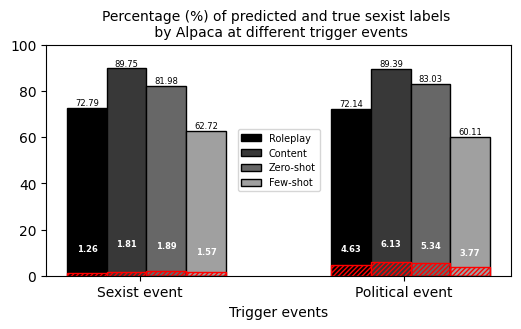

In [369]:
list_events = list(data_alpaca['trigger_event'].unique())
X_axis = np.arange(len(list_events)) 

fig, ax = plt.subplots(figsize=(6, 3))

#ax.bar(X_axis - 0.2, data_labels_label_neither, 0.2, label = 'Neither') 
ax.bar(X_axis - 0.20, percent_list_alp_r_1, 0.15, label = 'Roleplay', color='#000000', edgecolor='black') 
ax.bar(X_axis - 0.05, percent_list_alp_c_1, 0.15, label = 'Content', color='#383838', edgecolor='black') 
ax.bar(X_axis + 0.10, percent_list_alp_z_1, 0.15, label = 'Zero-shot', color='#676767', edgecolor='black') 
ax.bar(X_axis + 0.25, percent_list_alp_f_1, 0.15, label = 'Few-shot', color='#a0a0a0', edgecolor='black') 


ax.bar(X_axis - 0.20 , percent_list_alp_cor_r_1, 0.15, label = None, color='none', edgecolor='red', hatch = '///////') 
ax.bar(X_axis - 0.05, percent_list_alp_cor_c_1, 0.15, label = None, color='none', edgecolor='red', hatch = '///////') 
ax.bar(X_axis + 0.10 , percent_list_alp_cor_z_1, 0.15, label = None, color='none', edgecolor='red', hatch = '///////') 
ax.bar(X_axis + 0.25 , percent_list_alp_cor_f_1, 0.15, label = None, color='none', edgecolor='red', hatch = '///////') 

plt.xticks(X_axis, ['Sexist event', 'Political event',]) 
ax.set_xlabel("Trigger events") 
ax.set_ylabel("") 
ax.set_title("Percentage (%) of predicted and true sexist labels \n by Alpaca at different trigger events", fontdict={'fontsize': 10}) 

rects = ax.patches

# Make some labels.
labels_sexism = [f"{i}" for i in percent_list_alp_1]
labels_correct_sexism = [f"{i}" for i in percent_list_alp_cor_1]

for rect, label1, label2 in zip(rects, labels_sexism, labels_correct_sexism):
    height = rect.get_height()
    ax.text(
        rect.get_x() + rect.get_width() / 2, height + 0.3, label1, ha="center", va="bottom", fontsize=6
    )
    ax.text(
        rect.get_x() + rect.get_width() / 2, height / 7.5, label2, ha="center", va="bottom", fontsize=6, weight = 'bold', color = 'white'
    )


plt.ylim([0, 100])
plt.legend(fontsize=7, loc='center') 
plt.show() 

fig.savefig("../images/alpaca-correct-sexism.pdf", bbox_inches='tight')

### Flan-T5

In [13]:
y_n_flan, pred_n_flan = data_flan['label'], data_flan['roleplay']
y_o_flan, pred_o_flan = data_flan['label'], data_flan['content']
y_z_flan, pred_z_flan = data_flan['label'], data_flan['zero-shot']
y_f_flan, pred_f_flan = data_flan['label'], data_flan['few-shot']

score_table_flan = pd.DataFrame(columns=['prompt type', 'F1 score', 'Precision', 'Recall', 'Accuracy'])
score_table_flan['prompt type'] = ['Roleplay', 'Content', 'Zero-shot', 'Few-shot']

f1_n_flan = f1_score(y_true = y_n_flan, y_pred= pred_n_flan, average='macro')
f1_o_flan = f1_score(y_true = y_o_flan, y_pred= pred_o_flan, average='macro')
f1_z_flan = f1_score(y_true = y_z_flan, y_pred= pred_z_flan, average='macro')
f1_f_flan = f1_score(y_true = y_f_flan, y_pred= pred_f_flan, average='macro')

f1_scores_flan = [f1_n_flan, f1_o_flan, f1_z_flan, f1_f_flan]
score_table_flan['F1 score'] = f1_scores_flan

precision_n_flan = precision_score(y_true = y_n_flan, y_pred= pred_n_flan, average='macro')
precision_o_flan = precision_score(y_true = y_o_flan, y_pred= pred_o_flan, average='macro')
precision_z_flan = precision_score(y_true = y_z_flan, y_pred= pred_z_flan, average='macro')
precision_f_flan = precision_score(y_true = y_f_flan, y_pred= pred_f_flan, average='macro')

precision_scores_flan = [precision_n_flan, precision_o_flan, precision_z_flan, precision_f_flan]
score_table_flan['Precision'] = precision_scores_flan


recall_n_flan = recall_score(y_true = y_n_flan, y_pred= pred_n_flan, average='macro')
recall_o_flan = recall_score(y_true = y_o_flan, y_pred= pred_o_flan, average='macro')
recall_z_flan = recall_score(y_true = y_z_flan, y_pred= pred_z_flan, average='macro')
recall_f_flan = recall_score(y_true = y_f_flan, y_pred= pred_f_flan, average='macro')

recall_scores_flan = [recall_n_flan, recall_o_flan, recall_z_flan, recall_f_flan]
score_table_flan['Recall'] = recall_scores_flan

acc_n_flan = accuracy_score(y_true = y_n_flan, y_pred= pred_n_flan)
acc_o_flan = accuracy_score(y_true = y_o_flan, y_pred= pred_o_flan)
acc_z_flan = accuracy_score(y_true = y_z_flan, y_pred= pred_z_flan)
acc_f_flan = accuracy_score(y_true = y_f_flan, y_pred= pred_f_flan)

accuracy_scores_flan = [acc_n_flan, acc_o_flan, acc_z_flan, acc_f_flan]
score_table_flan['Accuracy'] = accuracy_scores_flan

score_table_flan[['F1 score', 'Precision', 'Recall', 'Accuracy']] = round(score_table_flan[['F1 score', 'Precision', 'Recall', 'Accuracy']] * 100, 2)
score_table_flan

,prompt type,F1 score,Precision,Recall,Accuracy
0,Roleplay,61.13,59.45,66.11,83.19
1,Content,60.85,59.28,64.80,83.82
2,Zero-shot,60.08,59.00,61.92,85.31
3,Few-shot,62.17,61.50,62.99,87.27


In [14]:
# roleplay
flan_r = data_flan[['trigger_event', 'roleplay']]
flan_r = flan_r.groupby('trigger_event')['roleplay'].value_counts().reset_index()
flan_r['percentage'] = round(100 * flan_r['count'] / flan_r.groupby('trigger_event')['count'].transform('sum'), 2)
flan_r = flan_r.sort_values(by='trigger_event')

flan_r_1 = flan_r[flan_r['roleplay'] == 1]['percentage'].to_list()
flan_r_0 = flan_r[flan_r['roleplay'] == 0]['percentage'].to_list()

flan_r_bylabel = flan_r.sort_values(by='roleplay')

percent_list_flan_r = flan_r_bylabel['percentage'].to_list()
percent_list_flan_r_1 = flan_r_bylabel[flan_r_bylabel['roleplay'] == 1]['percentage'].to_list()
percent_list_flan_r_0 = flan_r_bylabel[flan_r_bylabel['roleplay'] == 0]['percentage'].to_list()

# content
flan_c = data_flan[['trigger_event', 'content']]
flan_c = flan_c.groupby('trigger_event')['content'].value_counts().reset_index()
flan_c['percentage'] = round(100 * flan_c['count'] / flan_c.groupby('trigger_event')['count'].transform('sum'), 2)
flan_c = flan_c.sort_values(by='trigger_event')

flan_c_1 = flan_c[flan_c['content'] == 1]['percentage'].to_list()
flan_c_0 = flan_c[flan_c['content'] == 0]['percentage'].to_list()

flan_c_bylabel = flan_c.sort_values(by='content')

percent_list_flan_c = flan_c_bylabel['percentage'].to_list()
percent_list_flan_c_1 = flan_c_bylabel[flan_c_bylabel['content'] == 1]['percentage'].to_list()
percent_list_flan_c_0 = flan_c_bylabel[flan_c_bylabel['content'] == 0]['percentage'].to_list()

# zero-shot
flan_z = data_flan[['trigger_event', 'zero-shot']]
flan_z = flan_z.groupby('trigger_event')['zero-shot'].value_counts().reset_index()
flan_z['percentage'] = round(100 * flan_z['count'] / flan_z.groupby('trigger_event')['count'].transform('sum'), 2)
flan_z = flan_z.sort_values(by='trigger_event')

flan_z_1 = flan_z[flan_z['zero-shot'] == 1]['percentage'].to_list()
flan_z_0 = flan_z[flan_z['zero-shot'] == 0]['percentage'].to_list()

flan_z_bylabel = flan_z.sort_values(by='zero-shot')

percent_list_flan_z = flan_z_bylabel['percentage'].to_list()
percent_list_flan_z_1 = flan_z_bylabel[flan_z_bylabel['zero-shot'] == 1]['percentage'].to_list()
percent_list_flan_z_0 = flan_z_bylabel[flan_z_bylabel['zero-shot'] == 0]['percentage'].to_list()

# few-shot
flan_f = data_flan[['trigger_event', 'few-shot']]
flan_f = flan_f.groupby('trigger_event')['few-shot'].value_counts().reset_index()
flan_f['percentage'] = round(100 * flan_f['count'] / flan_f.groupby('trigger_event')['count'].transform('sum'), 2)
flan_f = flan_f.sort_values(by='trigger_event')

flan_f_1 = flan_f[flan_f['few-shot'] == 1]['percentage'].to_list()
flan_f_0 = flan_f[flan_f['few-shot'] == 0]['percentage'].to_list()

flan_f_bylabel = flan_f.sort_values(by='few-shot')

percent_list_flan_f = flan_f_bylabel['percentage'].to_list()
percent_list_flan_f_1 = flan_f_bylabel[flan_f_bylabel['few-shot'] == 1]['percentage'].to_list()
percent_list_flan_f_0 = flan_f_bylabel[flan_f_bylabel['few-shot'] == 0]['percentage'].to_list()

percent_list_flan_1 = [percent_list_flan_r_1, percent_list_flan_c_1, percent_list_flan_z_1, percent_list_flan_f_1]
percent_list_flan_1 = list(itertools.chain.from_iterable(percent_list_flan_1))

In [15]:
## roleplay
flan_cor_r = data_flan[['trigger_event', 'label', 'roleplay']].value_counts().reset_index()
flan_cor_r['percentage'] = round(100 * flan_cor_r['count'] / flan_cor_r['count'].sum(), 2)
flan_cor_r = flan_cor_r.sort_values(by='trigger_event')

flan_cor_r_1 = flan_cor_r[(flan_cor_r['label'] == 1) & (flan_cor_r['roleplay'] == 1)]
percent_list_flan_cor_r_1 = flan_cor_r_1['percentage'].to_list()
flan_cor_r_0 = flan_cor_r[(flan_cor_r['label'] == 0) & (flan_cor_r['roleplay'] == 0)]
percent_list_flan_cor_r_0 = flan_cor_r_0['percentage'].to_list()

# content
flan_cor_c = data_flan[['trigger_event', 'label', 'content']].value_counts().reset_index()
flan_cor_c['percentage'] = round(100 * flan_cor_c['count'] / flan_cor_c['count'].sum(), 2)
flan_cor_c = flan_cor_c.sort_values(by='trigger_event')

flan_cor_c_1 = flan_cor_c[(flan_cor_c['label'] == 1) & (flan_cor_c['content'] == 1)]
percent_list_flan_cor_c_1 = flan_cor_c_1['percentage'].to_list()
flan_cor_c_0 = flan_cor_c[(flan_cor_c['label'] == 0) & (flan_cor_c['content'] == 0)]
percent_list_flan_cor_c_0 = flan_cor_c_0['percentage'].to_list()

# zero-shot
flan_cor_z = data_flan[['trigger_event', 'label', 'zero-shot']].value_counts().reset_index()
flan_cor_z['percentage'] = round(100 * flan_cor_z['count'] / flan_cor_z['count'].sum(), 2)
flan_cor_z = flan_cor_z.sort_values(by='trigger_event')

flan_cor_z_1 = flan_cor_z[(flan_cor_z['label'] == 1) & (flan_cor_z['zero-shot'] == 1)]
percent_list_flan_cor_z_1 = flan_cor_z_1['percentage'].to_list()
flan_cor_z_0 = flan_cor_z[(flan_cor_z['label'] == 0) & (flan_cor_z['zero-shot'] == 0)]
percent_list_flan_cor_z_0 = flan_cor_z_0['percentage'].to_list()

# few-shot
flan_cor_f = data_flan[['trigger_event', 'label', 'few-shot']].value_counts().reset_index()
flan_cor_f['percentage'] = round(100 * flan_cor_f['count'] / flan_cor_f['count'].sum(), 2)
flan_cor_f = flan_cor_f.sort_values(by='trigger_event')

flan_cor_f_1 = flan_cor_f[(flan_cor_f['label'] == 1) & (flan_cor_f['few-shot'] == 1)]
percent_list_flan_cor_f_1 = flan_cor_f_1['percentage'].to_list()
flan_cor_f_0 = flan_cor_f[(flan_cor_f['label'] == 0) & (flan_cor_f['few-shot'] == 0)]
percent_list_flan_cor_f_0 = flan_cor_f_0['percentage'].to_list()

percent_list_flan_cor_1 = [percent_list_flan_cor_r_1, percent_list_flan_cor_c_1, percent_list_flan_cor_z_1, percent_list_flan_cor_f_1]
percent_list_flan_cor_1 = list(itertools.chain.from_iterable(percent_list_flan_cor_1))

percent_list_flan_cor_0 = [percent_list_flan_cor_r_0, percent_list_flan_cor_c_0, percent_list_flan_cor_z_0, percent_list_flan_cor_f_0]
percent_list_flan_cor_0 = list(itertools.chain.from_iterable(percent_list_flan_cor_0))

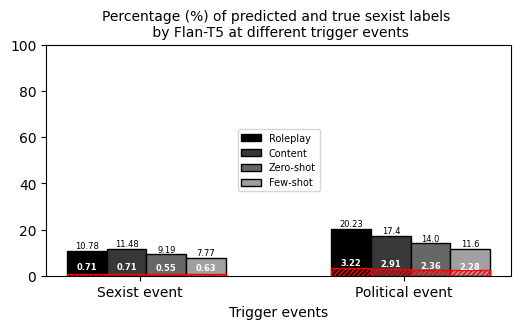

In [16]:
list_events = list(data_flan['trigger_event'].unique())
X_axis = np.arange(len(list_events)) 

fig, ax = plt.subplots(figsize=(6, 3))

#ax.bar(X_axis - 0.2, data_labels_label_neither, 0.2, label = 'Neither') 
ax.bar(X_axis - 0.20, percent_list_flan_r_1, 0.15, label = 'Roleplay', color='#000000', edgecolor='black') 
ax.bar(X_axis - 0.05, percent_list_flan_c_1, 0.15, label = 'Content', color='#383838', edgecolor='black') 
ax.bar(X_axis + 0.10, percent_list_flan_z_1, 0.15, label = 'Zero-shot', color='#676767', edgecolor='black') 
ax.bar(X_axis + 0.25, percent_list_flan_f_1, 0.15, label = 'Few-shot', color='#a0a0a0', edgecolor='black') 


ax.bar(X_axis - 0.20 , percent_list_flan_cor_r_1, 0.15, label = None, color='none', edgecolor='red', hatch = '///////') 
ax.bar(X_axis - 0.05, percent_list_flan_cor_c_1, 0.15, label = None, color='none', edgecolor='red', hatch = '///////') 
ax.bar(X_axis + 0.10 , percent_list_flan_cor_z_1, 0.15, label = None, color='none', edgecolor='red', hatch = '///////') 
ax.bar(X_axis + 0.25 , percent_list_flan_cor_f_1, 0.15, label = None, color='none', edgecolor='red', hatch = '///////') 

plt.xticks(X_axis, ['Sexist event', 'Political event',]) 
ax.set_xlabel("Trigger events") 
ax.set_ylabel("") 
ax.set_title("Percentage (%) of predicted and true sexist labels \n by Flan-T5 at different trigger events", fontdict={'fontsize': 10}) 

rects = ax.patches

# Make some labels.
labels_sexism = [f"{i}" for i in percent_list_flan_1]
labels_correct_sexism = [f"{i}" for i in percent_list_flan_cor_1]

for rect, label1, label2 in zip(rects, labels_sexism, labels_correct_sexism):
    height = rect.get_height()
    ax.text(
        rect.get_x() + rect.get_width() / 2, height + 0.3, label1, ha="center", va="bottom", fontsize=6
    )
    ax.text(
        rect.get_x() + rect.get_width() / 2, height / 5.5, label2, ha="center", va="bottom", fontsize=6, weight = 'bold', color = 'white'
    )


plt.ylim([0, 100])
plt.legend(fontsize=7, loc='center') 
plt.show() 

fig.savefig("../images/flan-correct-sexism.pdf", bbox_inches='tight')

### Vicuna

In [192]:
y_n_vic, pred_n_vic = data_vicuna['label'], data_vicuna['roleplay']
y_o_vic, pred_o_vic = data_vicuna['label'], data_vicuna['content']
y_z_vic, pred_z_vic = data_vicuna['label'], data_vicuna['zero-shot']
y_f_vic, pred_f_vic = data_vicuna['label'], data_vicuna['few-shot']

score_table_vic = pd.DataFrame(columns=['prompt type', 'F1 score', 'Precision', 'Recall', 'Accuracy'])
score_table_vic['prompt type'] = ['Roleplay', 'Content', 'Zero-shot', 'Few-shot']

f1_n_vic = f1_score(y_true = y_n_vic, y_pred= pred_n_vic, average='macro')
f1_o_vic = f1_score(y_true = y_o_vic, y_pred= pred_o_vic, average='macro')
f1_z_vic = f1_score(y_true = y_z_vic, y_pred= pred_z_vic, average='macro')
f1_f_vic = f1_score(y_true = y_f_vic, y_pred= pred_f_vic, average='macro')

f1_scores_vic = [f1_n_vic, f1_o_vic, f1_z_vic, f1_f_vic]
score_table_vic['F1 score'] = f1_scores_vic

precision_n_vic = precision_score(y_true = y_n_vic, y_pred= pred_n_vic, average='macro')
precision_o_vic = precision_score(y_true = y_o_vic, y_pred= pred_o_vic, average='macro')
precision_z_vic = precision_score(y_true = y_z_vic, y_pred= pred_z_vic, average='macro')
precision_f_vic = precision_score(y_true = y_f_vic, y_pred= pred_f_vic, average='macro')

precision_scores_vic = [precision_n_vic, precision_o_vic, precision_z_vic, precision_f_vic]
score_table_vic['Precision'] = precision_scores_vic


recall_n_vic = recall_score(y_true = y_n_vic, y_pred= pred_n_vic, average='macro')
recall_o_vic = recall_score(y_true = y_o_vic, y_pred= pred_o_vic, average='macro')
recall_z_vic = recall_score(y_true = y_z_vic, y_pred= pred_z_vic, average='macro')
recall_f_vic = recall_score(y_true = y_f_vic, y_pred= pred_f_vic, average='macro')

recall_scores_vic = [recall_n_vic, recall_o_vic, recall_z_vic, recall_f_vic]
score_table_vic['Recall'] = recall_scores_vic

acc_n_vic = accuracy_score(y_true = y_n_vic, y_pred= pred_n_vic)
acc_o_vic = accuracy_score(y_true = y_o_vic, y_pred= pred_o_vic)
acc_z_vic = accuracy_score(y_true = y_z_vic, y_pred= pred_z_vic)
acc_f_vic = accuracy_score(y_true = y_f_vic, y_pred= pred_f_vic)

accuracy_scores_vic = [acc_n_vic, acc_o_vic, acc_z_vic, acc_f_vic]
score_table_vic['Accuracy'] = accuracy_scores_vic

score_table_vic[['F1 score', 'Precision', 'Recall', 'Accuracy']] = round(score_table_vic[['F1 score', 'Precision', 'Recall', 'Accuracy']] * 100, 2)
score_table_vic

,prompt type,F1 score,Precision,Recall,Accuracy
0,Roleplay,37.51,50.35,51.10,45.25
1,Content,45.84,50.92,52.70,62.45
2,Zero-shot,47.12,51.47,54.19,64.41
3,Few-shot,48.31,48.39,48.24,82.88


In [285]:
# roleplay
vic_r = data_vicuna[['trigger_event', 'roleplay']]
vic_r = vic_r.groupby('trigger_event')['roleplay'].value_counts().reset_index()
vic_r['percentage'] = round(100 * vic_r['count'] / vic_r.groupby('trigger_event')['count'].transform('sum'), 2)
vic_r = vic_r.sort_values(by='trigger_event')

vic_r_1 = vic_r[vic_r['roleplay'] == 1]['percentage'].to_list()
vic_r_0 = vic_r[vic_r['roleplay'] == 0]['percentage'].to_list()

vic_r_bylabel = vic_r.sort_values(by='roleplay')

percent_list_vic_r = vic_r_bylabel['percentage'].to_list()
percent_list_vic_r_1 = vic_r_bylabel[vic_r_bylabel['roleplay'] == 1]['percentage'].to_list()
percent_list_vic_r_0 = vic_r_bylabel[vic_r_bylabel['roleplay'] == 0]['percentage'].to_list()

# content
vic_c = data_vicuna[['trigger_event', 'content']]
vic_c = vic_c.groupby('trigger_event')['content'].value_counts().reset_index()
vic_c['percentage'] = round(100 * vic_c['count'] / vic_c.groupby('trigger_event')['count'].transform('sum'), 2)
vic_c = vic_c.sort_values(by='trigger_event')

vic_c_1 = vic_c[vic_c['content'] == 1]['percentage'].to_list()
vic_c_0 = vic_c[vic_c['content'] == 0]['percentage'].to_list()

vic_c_bylabel = vic_c.sort_values(by='content')

percent_list_vic_c = vic_c_bylabel['percentage'].to_list()
percent_list_vic_c_1 = vic_c_bylabel[vic_c_bylabel['content'] == 1]['percentage'].to_list()
percent_list_vic_c_0 = vic_c_bylabel[vic_c_bylabel['content'] == 0]['percentage'].to_list()

# zero-shot
vic_z = data_vicuna[['trigger_event', 'zero-shot']]
vic_z = vic_z.groupby('trigger_event')['zero-shot'].value_counts().reset_index()
vic_z['percentage'] = round(100 * vic_z['count'] / vic_z.groupby('trigger_event')['count'].transform('sum'), 2)
vic_z = vic_z.sort_values(by='trigger_event')

vic_z_1 = vic_z[vic_z['zero-shot'] == 1]['percentage'].to_list()
vic_z_0 = vic_z[vic_z['zero-shot'] == 0]['percentage'].to_list()

vic_z_bylabel = vic_z.sort_values(by='zero-shot')

percent_list_vic_z = vic_z_bylabel['percentage'].to_list()
percent_list_vic_z_1 = vic_z_bylabel[vic_z_bylabel['zero-shot'] == 1]['percentage'].to_list()
percent_list_vic_z_0 = vic_z_bylabel[vic_z_bylabel['zero-shot'] == 0]['percentage'].to_list()

# few-shot
vic_f = data_vicuna[['trigger_event', 'few-shot']]
vic_f = vic_f.groupby('trigger_event')['few-shot'].value_counts().reset_index()
vic_f['percentage'] = round(100 * vic_f['count'] / vic_f.groupby('trigger_event')['count'].transform('sum'), 2)
vic_f = vic_f.sort_values(by='trigger_event')

vic_f_1 = vic_f[vic_f['few-shot'] == 1]['percentage'].to_list()
vic_f_0 = vic_f[vic_f['few-shot'] == 0]['percentage'].to_list()

vic_f_bylabel = vic_f.sort_values(by='few-shot')

percent_list_vic_f = vic_f_bylabel['percentage'].to_list()
percent_list_vic_f_1 = vic_f_bylabel[vic_f_bylabel['few-shot'] == 1]['percentage'].to_list()
percent_list_vic_f_0 = vic_f_bylabel[vic_f_bylabel['few-shot'] == 0]['percentage'].to_list()

percent_list_vic_1 = [percent_list_vic_r_1, percent_list_vic_c_1, percent_list_vic_z_1, percent_list_vic_f_1]
percent_list_vic_1 = list(itertools.chain.from_iterable(percent_list_vic_1))

In [286]:
## roleplay
vic_cor_r = data_vicuna[['trigger_event', 'label', 'roleplay']].value_counts().reset_index()
vic_cor_r['percentage'] = round(100 * vic_cor_r['count'] / vic_cor_r['count'].sum(), 2)
vic_cor_r = vic_cor_r.sort_values(by='trigger_event')

vic_cor_r_1 = vic_cor_r[(vic_cor_r['label'] == 1) & (vic_cor_r['roleplay'] == 1)]
percent_list_vic_cor_r_1 = vic_cor_r_1['percentage'].to_list()
vic_cor_r_0 = vic_cor_r[(vic_cor_r['label'] == 0) & (vic_cor_r['roleplay'] == 0)]
percent_list_vic_cor_r_0 = vic_cor_r_0['percentage'].to_list()

# content
vic_cor_c = data_vicuna[['trigger_event', 'label', 'content']].value_counts().reset_index()
vic_cor_c['percentage'] = round(100 * vic_cor_c['count'] / vic_cor_c['count'].sum(), 2)
vic_cor_c = vic_cor_c.sort_values(by='trigger_event')

vic_cor_c_1 = vic_cor_c[(vic_cor_c['label'] == 1) & (vic_cor_c['content'] == 1)]
percent_list_vic_cor_c_1 = vic_cor_c_1['percentage'].to_list()
vic_cor_c_0 = vic_cor_c[(vic_cor_c['label'] == 0) & (vic_cor_c['content'] == 0)]
percent_list_vic_cor_c_0 = vic_cor_c_0['percentage'].to_list()

# zero-shot
vic_cor_z = data_vicuna[['trigger_event', 'label', 'zero-shot']].value_counts().reset_index()
vic_cor_z['percentage'] = round(100 * vic_cor_z['count'] / vic_cor_z['count'].sum(), 2)
vic_cor_z = vic_cor_z.sort_values(by='trigger_event')

vic_cor_z_1 = vic_cor_z[(vic_cor_z['label'] == 1) & (vic_cor_z['zero-shot'] == 1)]
percent_list_vic_cor_z_1 = vic_cor_z_1['percentage'].to_list()
vic_cor_z_0 = vic_cor_z[(vic_cor_z['label'] == 0) & (vic_cor_z['zero-shot'] == 0)]
percent_list_vic_cor_z_0 = vic_cor_z_0['percentage'].to_list()

# few-shot
vic_cor_f = data_vicuna[['trigger_event', 'label', 'few-shot']].value_counts().reset_index()
vic_cor_f['percentage'] = round(100 * vic_cor_f['count'] / vic_cor_f['count'].sum(), 2)
vic_cor_f = vic_cor_f.sort_values(by='trigger_event')

vic_cor_f_1 = vic_cor_f[(vic_cor_f['label'] == 1) & (vic_cor_f['few-shot'] == 1)]
percent_list_vic_cor_f_1 = vic_cor_f_1['percentage'].to_list()
vic_cor_f_0 = vic_cor_f[(vic_cor_f['label'] == 0) & (vic_cor_f['few-shot'] == 0)]
percent_list_vic_cor_f_0 = vic_cor_f_0['percentage'].to_list()

percent_list_vic_cor_1 = [percent_list_vic_cor_r_1, percent_list_vic_cor_c_1, percent_list_vic_cor_z_1, percent_list_vic_cor_f_1]
percent_list_vic_cor_1 = list(itertools.chain.from_iterable(percent_list_vic_cor_1))

percent_list_vic_cor_0 = [percent_list_vic_cor_r_0, percent_list_vic_cor_c_0, percent_list_vic_cor_z_0, percent_list_vic_cor_f_0]
percent_list_vic_cor_0 = list(itertools.chain.from_iterable(percent_list_vic_cor_0))

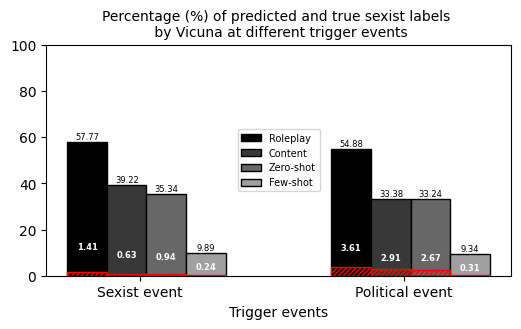

In [367]:
list_events = list(data_vicuna['trigger_event'].unique())
X_axis = np.arange(len(list_events)) 

fig, ax = plt.subplots(figsize=(6, 3))

#ax.bar(X_axis - 0.2, data_labels_label_neither, 0.2, label = 'Neither') 
ax.bar(X_axis - 0.20, percent_list_vic_r_1, 0.15, label = 'Roleplay', color='#000000', edgecolor='black') 
ax.bar(X_axis - 0.05, percent_list_vic_c_1, 0.15, label = 'Content', color='#383838', edgecolor='black') 
ax.bar(X_axis + 0.10, percent_list_vic_z_1, 0.15, label = 'Zero-shot', color='#676767', edgecolor='black') 
ax.bar(X_axis + 0.25, percent_list_vic_f_1, 0.15, label = 'Few-shot', color='#a0a0a0', edgecolor='black') 


ax.bar(X_axis - 0.20 , percent_list_vic_cor_r_1, 0.15, label = None, color='none', edgecolor='red', hatch = '///////') 
ax.bar(X_axis - 0.05, percent_list_vic_cor_c_1, 0.15, label = None, color='none', edgecolor='red', hatch = '///////') 
ax.bar(X_axis + 0.10 , percent_list_vic_cor_z_1, 0.15, label = None, color='none', edgecolor='red', hatch = '///////') 
ax.bar(X_axis + 0.25 , percent_list_vic_cor_f_1, 0.15, label = None, color='none', edgecolor='red', hatch = '///////') 

plt.xticks(X_axis, ['Sexist event', 'Political event',]) 
ax.set_xlabel("Trigger events") 
ax.set_ylabel("") 
ax.set_title("Percentage (%) of predicted and true sexist labels \n by Vicuna at different trigger events", fontdict={'fontsize': 10}) 

rects = ax.patches

# Make some labels.
labels_sexism = [f"{i}" for i in percent_list_vic_1]
labels_correct_sexism = [f"{i}" for i in percent_list_vic_cor_1]

for rect, label1, label2 in zip(rects, labels_sexism, labels_correct_sexism):
    height = rect.get_height()
    ax.text(
        rect.get_x() + rect.get_width() / 2, height + 0.3, label1, ha="center", va="bottom", fontsize=6
    )
    ax.text(
        rect.get_x() + rect.get_width() / 2, height / 5.5, label2, ha="center", va="bottom", fontsize=6, weight = 'bold', color = 'white'
    )


plt.ylim([0, 100])
plt.legend(fontsize=7, loc='center') 
plt.show() 

fig.savefig("../images/vicuna-correct-sexism.pdf", bbox_inches='tight')

### Mistral

In [193]:
y_n_mis, pred_n_mis = data_mistral['label'], data_mistral['roleplay']
y_o_mis, pred_o_mis = data_mistral['label'], data_mistral['content']
y_z_mis, pred_z_mis = data_mistral['label'], data_mistral['zero-shot']
y_f_mis, pred_f_mis = data_mistral['label'], data_mistral['few-shot']

score_table_mis = pd.DataFrame(columns=['prompt type', 'F1 score', 'Precision', 'Recall', 'Accuracy'])
score_table_mis['prompt type'] = ['Roleplay', 'Content', 'Zero-shot', 'Few-shot']

f1_n_mis = f1_score(y_true = y_n_mis, y_pred= pred_n_mis, average='macro')
f1_o_mis = f1_score(y_true = y_o_mis, y_pred= pred_o_mis, average='macro')
f1_z_mis = f1_score(y_true = y_z_mis, y_pred= pred_z_mis, average='macro')
f1_f_mis = f1_score(y_true = y_f_mis, y_pred= pred_f_mis, average='macro')

f1_scores_mis = [f1_n_mis, f1_o_mis, f1_z_mis, f1_f_mis]
score_table_mis['F1 score'] = f1_scores_mis

precision_n_mis = precision_score(y_true = y_n_mis, y_pred= pred_n_mis, average='macro')
precision_o_mis = precision_score(y_true = y_o_mis, y_pred= pred_o_mis, average='macro')
precision_z_mis = precision_score(y_true = y_z_mis, y_pred= pred_z_mis, average='macro')
precision_f_mis = precision_score(y_true = y_f_mis, y_pred= pred_f_mis, average='macro')

precision_scores_mis = [precision_n_mis, precision_o_mis, precision_z_mis, precision_f_mis]
score_table_mis['Precision'] = precision_scores_mis


recall_n_mis = recall_score(y_true = y_n_mis, y_pred= pred_n_mis, average='macro')
recall_o_mis = recall_score(y_true = y_o_mis, y_pred= pred_o_mis, average='macro')
recall_z_mis = recall_score(y_true = y_z_mis, y_pred= pred_z_mis, average='macro')
recall_f_mis = recall_score(y_true = y_f_mis, y_pred= pred_f_mis, average='macro')

recall_scores_mis = [recall_n_mis, recall_o_mis, recall_z_mis, recall_f_mis]
score_table_mis['Recall'] = recall_scores_mis

acc_n_mis = accuracy_score(y_true = y_n_mis, y_pred= pred_n_mis)
acc_o_mis = accuracy_score(y_true = y_o_mis, y_pred= pred_o_mis)
acc_z_mis = accuracy_score(y_true = y_z_mis, y_pred= pred_z_mis)
acc_f_mis = accuracy_score(y_true = y_f_mis, y_pred= pred_f_mis)

accuracy_scores_mis = [acc_n_mis, acc_o_mis, acc_z_mis, acc_f_mis]
score_table_mis['Accuracy'] = accuracy_scores_mis

score_table_mis[['F1 score', 'Precision', 'Recall', 'Accuracy']] = round(score_table_mis[['F1 score', 'Precision', 'Recall', 'Accuracy']] * 100, 2)
score_table_mis

,prompt type,F1 score,Precision,Recall,Accuracy
0,Roleplay,48.25,48.46,48.13,81.93
1,Content,49.06,49.77,49.60,77.85
2,Zero-shot,49.37,49.87,49.79,78.95
3,Few-shot,49.22,49.26,49.52,86.72


In [289]:
# roleplay
mis_r = data_mistral[['trigger_event', 'roleplay']]
mis_r = mis_r.groupby('trigger_event')['roleplay'].value_counts().reset_index()
mis_r['percentage'] = round(100 * mis_r['count'] / mis_r.groupby('trigger_event')['count'].transform('sum'), 2)
mis_r = mis_r.sort_values(by='trigger_event')

mis_r_1 = mis_r[mis_r['roleplay'] == 1]['percentage'].to_list()
mis_r_0 = mis_r[mis_r['roleplay'] == 0]['percentage'].to_list()

mis_r_bylabel = mis_r.sort_values(by='roleplay')

percent_list_mis_r = mis_r_bylabel['percentage'].to_list()
percent_list_mis_r_1 = mis_r_bylabel[mis_r_bylabel['roleplay'] == 1]['percentage'].to_list()
percent_list_mis_r_0 = mis_r_bylabel[mis_r_bylabel['roleplay'] == 0]['percentage'].to_list()

# content
mis_c = data_mistral[['trigger_event', 'content']]
mis_c = mis_c.groupby('trigger_event')['content'].value_counts().reset_index()
mis_c['percentage'] = round(100 * mis_c['count'] / mis_c.groupby('trigger_event')['count'].transform('sum'), 2)
mis_c = mis_c.sort_values(by='trigger_event')

mis_c_1 = mis_c[mis_c['content'] == 1]['percentage'].to_list()
mis_c_0 = mis_c[mis_c['content'] == 0]['percentage'].to_list()

mis_c_bylabel = mis_c.sort_values(by='content')

percent_list_mis_c = mis_c_bylabel['percentage'].to_list()
percent_list_mis_c_1 = mis_c_bylabel[mis_c_bylabel['content'] == 1]['percentage'].to_list()
percent_list_mis_c_0 = mis_c_bylabel[mis_c_bylabel['content'] == 0]['percentage'].to_list()

# zero-shot
mis_z = data_mistral[['trigger_event', 'zero-shot']]
mis_z = mis_z.groupby('trigger_event')['zero-shot'].value_counts().reset_index()
mis_z['percentage'] = round(100 * mis_z['count'] / mis_z.groupby('trigger_event')['count'].transform('sum'), 2)
mis_z = mis_z.sort_values(by='trigger_event')

mis_z_1 = mis_z[mis_z['zero-shot'] == 1]['percentage'].to_list()
mis_z_0 = mis_z[mis_z['zero-shot'] == 0]['percentage'].to_list()

mis_z_bylabel = mis_z.sort_values(by='zero-shot')

percent_list_mis_z = mis_z_bylabel['percentage'].to_list()
percent_list_mis_z_1 = mis_z_bylabel[mis_z_bylabel['zero-shot'] == 1]['percentage'].to_list()
percent_list_mis_z_0 = mis_z_bylabel[mis_z_bylabel['zero-shot'] == 0]['percentage'].to_list()

# few-shot
mis_f = data_mistral[['trigger_event', 'few-shot']]
mis_f = mis_f.groupby('trigger_event')['few-shot'].value_counts().reset_index()
mis_f['percentage'] = round(100 * mis_f['count'] / mis_f.groupby('trigger_event')['count'].transform('sum'), 2)
mis_f = mis_f.sort_values(by='trigger_event')

mis_f_1 = mis_f[mis_f['few-shot'] == 1]['percentage'].to_list()
mis_f_0 = mis_f[mis_f['few-shot'] == 0]['percentage'].to_list()

mis_f_bylabel = mis_f.sort_values(by='few-shot')

percent_list_mis_f = mis_f_bylabel['percentage'].to_list()
percent_list_mis_f_1 = mis_f_bylabel[mis_f_bylabel['few-shot'] == 1]['percentage'].to_list()
percent_list_mis_f_0 = mis_f_bylabel[mis_f_bylabel['few-shot'] == 0]['percentage'].to_list()

percent_list_mis_1 = [percent_list_mis_r_1, percent_list_mis_c_1, percent_list_mis_z_1, percent_list_mis_f_1]
percent_list_mis_1 = list(itertools.chain.from_iterable(percent_list_mis_1))

In [290]:
## roleplay
mis_cor_r = data_mistral[['trigger_event', 'label', 'roleplay']].value_counts().reset_index()
mis_cor_r['percentage'] = round(100 * mis_cor_r['count'] / mis_cor_r['count'].sum(), 2)
mis_cor_r = mis_cor_r.sort_values(by='trigger_event')

mis_cor_r_1 = mis_cor_r[(mis_cor_r['label'] == 1) & (mis_cor_r['roleplay'] == 1)]
percent_list_mis_cor_r_1 = mis_cor_r_1['percentage'].to_list()
mis_cor_r_0 = mis_cor_r[(mis_cor_r['label'] == 0) & (mis_cor_r['roleplay'] == 0)]
percent_list_mis_cor_r_0 = mis_cor_r_0['percentage'].to_list()

# content
mis_cor_c = data_mistral[['trigger_event', 'label', 'content']].value_counts().reset_index()
mis_cor_c['percentage'] = round(100 * mis_cor_c['count'] / mis_cor_c['count'].sum(), 2)
mis_cor_c = mis_cor_c.sort_values(by='trigger_event')

mis_cor_c_1 = mis_cor_c[(mis_cor_c['label'] == 1) & (mis_cor_c['content'] == 1)]
percent_list_mis_cor_c_1 = mis_cor_c_1['percentage'].to_list()
mis_cor_c_0 = mis_cor_c[(mis_cor_c['label'] == 0) & (mis_cor_c['content'] == 0)]
percent_list_mis_cor_c_0 = mis_cor_c_0['percentage'].to_list()

# zero-shot
mis_cor_z = data_mistral[['trigger_event', 'label', 'zero-shot']].value_counts().reset_index()
mis_cor_z['percentage'] = round(100 * mis_cor_z['count'] / mis_cor_z['count'].sum(), 2)
mis_cor_z = mis_cor_z.sort_values(by='trigger_event')

mis_cor_z_1 = mis_cor_z[(mis_cor_z['label'] == 1) & (mis_cor_z['zero-shot'] == 1)]
percent_list_mis_cor_z_1 = mis_cor_z_1['percentage'].to_list()
mis_cor_z_0 = mis_cor_z[(mis_cor_z['label'] == 0) & (mis_cor_z['zero-shot'] == 0)]
percent_list_mis_cor_z_0 = mis_cor_z_0['percentage'].to_list()

# few-shot
mis_cor_f = data_mistral[['trigger_event', 'label', 'few-shot']].value_counts().reset_index()
mis_cor_f['percentage'] = round(100 * mis_cor_f['count'] / mis_cor_f['count'].sum(), 2)
mis_cor_f = mis_cor_f.sort_values(by='trigger_event')

mis_cor_f_1 = mis_cor_f[(mis_cor_f['label'] == 1) & (mis_cor_f['few-shot'] == 1)]
percent_list_mis_cor_f_1 = mis_cor_f_1['percentage'].to_list()
mis_cor_f_0 = mis_cor_f[(mis_cor_f['label'] == 0) & (mis_cor_f['few-shot'] == 0)]
percent_list_mis_cor_f_0 = mis_cor_f_0['percentage'].to_list()

percent_list_mis_cor_1 = [percent_list_mis_cor_r_1, percent_list_mis_cor_c_1, percent_list_mis_cor_z_1, percent_list_mis_cor_f_1]
percent_list_mis_cor_1 = list(itertools.chain.from_iterable(percent_list_mis_cor_1))

percent_list_mis_cor_0 = [percent_list_mis_cor_r_0, percent_list_mis_cor_c_0, percent_list_mis_cor_z_0, percent_list_mis_cor_f_0]
percent_list_mis_cor_0 = list(itertools.chain.from_iterable(percent_list_mis_cor_0))

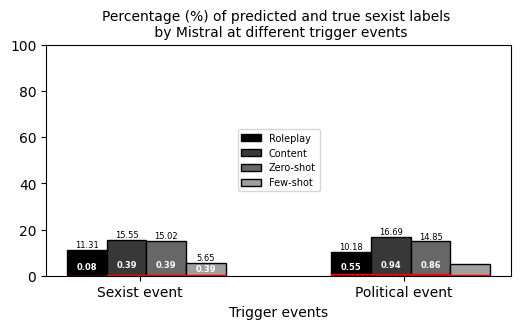

In [366]:
list_events = list(data_mistral['trigger_event'].unique())
X_axis = np.arange(len(list_events)) 

fig, ax = plt.subplots(figsize=(6, 3))

#ax.bar(X_axis - 0.2, data_labels_label_neither, 0.2, label = 'Neither') 
ax.bar(X_axis - 0.20, percent_list_mis_r_1, 0.15, label = 'Roleplay', color='#000000', edgecolor='black') 
ax.bar(X_axis - 0.05, percent_list_mis_c_1, 0.15, label = 'Content', color='#383838', edgecolor='black') 
ax.bar(X_axis + 0.10, percent_list_mis_z_1, 0.15, label = 'Zero-shot', color='#676767', edgecolor='black') 
ax.bar(X_axis + 0.25, percent_list_mis_f_1, 0.15, label = 'Few-shot', color='#a0a0a0', edgecolor='black') 


ax.bar(X_axis - 0.20 , percent_list_mis_cor_r_1, 0.15, label = None, color='none', edgecolor='red', hatch = '///////') 
ax.bar(X_axis - 0.05, percent_list_mis_cor_c_1, 0.15, label = None, color='none', edgecolor='red', hatch = '///////') 
ax.bar(X_axis + 0.10 , percent_list_mis_cor_z_1, 0.15, label = None, color='none', edgecolor='red', hatch = '///////') 
ax.bar(X_axis + 0.25 , percent_list_mis_cor_f_1, 0.15, label = None, color='none', edgecolor='red', hatch = '///////') 

plt.xticks(X_axis, ['Sexist event', 'Political event',]) 
ax.set_xlabel("Trigger events") 
ax.set_ylabel("") 
ax.set_title("Percentage (%) of predicted and true sexist labels \n by Mistral at different trigger events", fontdict={'fontsize': 10}) 

rects = ax.patches

# Make some labels.
labels_sexism = [f"{i}" for i in percent_list_mis_1]
labels_correct_sexism = [f"{i}" for i in percent_list_mis_cor_1]

for rect, label1, label2 in zip(rects, labels_sexism, labels_correct_sexism):
    height = rect.get_height()
    ax.text(
        rect.get_x() + rect.get_width() / 2, height + 0.3, label1, ha="center", va="bottom", fontsize=6
    )
    ax.text(
        rect.get_x() + rect.get_width() / 2, height / 5.5, label2, ha="center", va="bottom", fontsize=6, weight = 'bold', color = 'white'
    )


plt.ylim([0, 100])
plt.legend(fontsize=7, loc='center') 
plt.show() 

fig.savefig("../images/mistral-correct-sexism.pdf", bbox_inches='tight')

### All of the models together

In [305]:
## Alpaca

alp_0_r = data_alpaca[['label', 'roleplay']].value_counts().reset_index()
alp_0_r['percentage'] = round(100 * alp_0_r['count'] / alp_0_r['count'].sum(), 2)
alp_0_r = alp_0_r[(alp_0_r['label'] == 0) & (alp_0_r['roleplay'] == 0)]
alp_0_r = alp_0_r['percentage'].to_list()

alp_0_c = data_alpaca[['label', 'content']].value_counts().reset_index()
alp_0_c['percentage'] = round(100 * alp_0_c['count'] / alp_0_c['count'].sum(), 2)
alp_0_c = alp_0_c[(alp_0_c['label'] == 0) & (alp_0_c['content'] == 0)]
alp_0_c = alp_0_c['percentage'].to_list()

alp_0_z = data_alpaca[['label', 'zero-shot']].value_counts().reset_index()
alp_0_z['percentage'] = round(100 * alp_0_z['count'] / alp_0_z['count'].sum(), 2)
alp_0_z = alp_0_z[(alp_0_z['label'] == 0) & (alp_0_z['zero-shot'] == 0)]
alp_0_z = alp_0_z['percentage'].to_list()

alp_0_f = data_alpaca[['label', 'few-shot']].value_counts().reset_index()
alp_0_f['percentage'] = round(100 * alp_0_f['count'] / alp_0_f['count'].sum(), 2)
alp_0_f = alp_0_f[(alp_0_f['label'] == 0) & (alp_0_f['few-shot'] == 0)]
alp_0_f = alp_0_f['percentage'].to_list()

p_alp_0 = [alp_0_r, alp_0_c, alp_0_z, alp_0_f]
p_alp_0 = list(itertools.chain.from_iterable(p_alp_0))


## Flan T-5

flan_0_r = data_flan[['label', 'roleplay']].value_counts().reset_index()
flan_0_r['percentage'] = round(100 * flan_0_r['count'] / flan_0_r['count'].sum(), 2)
flan_0_r = flan_0_r[(flan_0_r['label'] == 0) & (flan_0_r['roleplay'] == 0)]
flan_0_r = flan_0_r['percentage'].to_list()

flan_0_c = data_flan[['label', 'content']].value_counts().reset_index()
flan_0_c['percentage'] = round(100 * flan_0_c['count'] / flan_0_c['count'].sum(), 2)
flan_0_c = flan_0_c[(flan_0_c['label'] == 0) & (flan_0_c['content'] == 0)]
flan_0_c = flan_0_c['percentage'].to_list()

flan_0_z = data_flan[['label', 'zero-shot']].value_counts().reset_index()
flan_0_z['percentage'] = round(100 * flan_0_z['count'] / flan_0_z['count'].sum(), 2)
flan_0_z = flan_0_z[(flan_0_z['label'] == 0) & (flan_0_z['zero-shot'] == 0)]
flan_0_z = flan_0_z['percentage'].to_list()

flan_0_f = data_flan[['label', 'few-shot']].value_counts().reset_index()
flan_0_f['percentage'] = round(100 * flan_0_f['count'] / flan_0_f['count'].sum(), 2)
flan_0_f = flan_0_f[(flan_0_f['label'] == 0) & (flan_0_f['few-shot'] == 0)]
flan_0_f = flan_0_f['percentage'].to_list()

p_flan_0 = [flan_0_r, flan_0_c, flan_0_z, flan_0_f]
p_flan_0 = list(itertools.chain.from_iterable(p_flan_0))


## GPT

gpt_0_r = data_gpt[['label', 'roleplay']].value_counts().reset_index()
gpt_0_r['percentage'] = round(100 * gpt_0_r['count'] / gpt_0_r['count'].sum(), 2)
gpt_0_r = gpt_0_r[(gpt_0_r['label'] == 0) & (gpt_0_r['roleplay'] == 0)]
gpt_0_r = gpt_0_r['percentage'].to_list()

gpt_0_c = data_gpt[['label', 'content']].value_counts().reset_index()
gpt_0_c['percentage'] = round(100 * gpt_0_c['count'] / gpt_0_c['count'].sum(), 2)
gpt_0_c = gpt_0_c[(gpt_0_c['label'] == 0) & (gpt_0_c['content'] == 0)]
gpt_0_c = gpt_0_c['percentage'].to_list()

gpt_0_z = data_gpt[['label', 'zero-shot']].value_counts().reset_index()
gpt_0_z['percentage'] = round(100 * gpt_0_z['count'] / gpt_0_z['count'].sum(), 2)
gpt_0_z = gpt_0_z[(gpt_0_z['label'] == 0) & (gpt_0_z['zero-shot'] == 0)]
gpt_0_z = gpt_0_z['percentage'].to_list()

gpt_0_f = data_gpt[['label', 'few-shot']].value_counts().reset_index()
gpt_0_f['percentage'] = round(100 * gpt_0_f['count'] / gpt_0_f['count'].sum(), 2)
gpt_0_f = gpt_0_f[(gpt_0_f['label'] == 0) & (gpt_0_f['few-shot'] == 0)]
gpt_0_f = gpt_0_f['percentage'].to_list()

p_gpt_0 = [gpt_0_r, gpt_0_c, gpt_0_z, gpt_0_f]
p_gpt_0 = list(itertools.chain.from_iterable(p_gpt_0))


## Vicuna

vic_0_r = data_vicuna[['label', 'roleplay']].value_counts().reset_index()
vic_0_r['percentage'] = round(100 * vic_0_r['count'] / vic_0_r['count'].sum(), 2)
vic_0_r = vic_0_r[(vic_0_r['label'] == 0) & (vic_0_r['roleplay'] == 0)]
vic_0_r = vic_0_r['percentage'].to_list()

vic_0_c = data_vicuna[['label', 'content']].value_counts().reset_index()
vic_0_c['percentage'] = round(100 * vic_0_c['count'] / vic_0_c['count'].sum(), 2)
vic_0_c = vic_0_c[(vic_0_c['label'] == 0) & (vic_0_c['content'] == 0)]
vic_0_c = vic_0_c['percentage'].to_list()

vic_0_z = data_vicuna[['label', 'zero-shot']].value_counts().reset_index()
vic_0_z['percentage'] = round(100 * vic_0_z['count'] / vic_0_z['count'].sum(), 2)
vic_0_z = vic_0_z[(vic_0_z['label'] == 0) & (vic_0_z['zero-shot'] == 0)]
vic_0_z = vic_0_z['percentage'].to_list()

vic_0_f = data_vicuna[['label', 'few-shot']].value_counts().reset_index()
vic_0_f['percentage'] = round(100 * vic_0_f['count'] / vic_0_f['count'].sum(), 2)
vic_0_f = vic_0_f[(vic_0_f['label'] == 0) & (vic_0_f['few-shot'] == 0)]
vic_0_f = vic_0_f['percentage'].to_list()

p_vic_0 = [vic_0_r, vic_0_c, vic_0_z, vic_0_f]
p_vic_0 = list(itertools.chain.from_iterable(p_vic_0))


## Mistral

mis_0_r = data_mistral[['label', 'roleplay']].value_counts().reset_index()
mis_0_r['percentage'] = round(100 * mis_0_r['count'] / mis_0_r['count'].sum(), 2)
mis_0_r = mis_0_r[(mis_0_r['label'] == 0) & (mis_0_r['roleplay'] == 0)]
mis_0_r = mis_0_r['percentage'].to_list()

mis_0_c = data_mistral[['label', 'content']].value_counts().reset_index()
mis_0_c['percentage'] = round(100 * mis_0_c['count'] / mis_0_c['count'].sum(), 2)
mis_0_c = mis_0_c[(mis_0_c['label'] == 0) & (mis_0_c['content'] == 0)]
mis_0_c = mis_0_c['percentage'].to_list()

mis_0_z = data_mistral[['label', 'zero-shot']].value_counts().reset_index()
mis_0_z['percentage'] = round(100 * mis_0_z['count'] / mis_0_z['count'].sum(), 2)
mis_0_z = mis_0_z[(mis_0_z['label'] == 0) & (mis_0_z['zero-shot'] == 0)]
mis_0_z = mis_0_z['percentage'].to_list()

mis_0_f = data_mistral[['label', 'few-shot']].value_counts().reset_index()
mis_0_f['percentage'] = round(100 * mis_0_f['count'] / mis_0_f['count'].sum(), 2)
mis_0_f = mis_0_f[(mis_0_f['label'] == 0) & (mis_0_f['few-shot'] == 0)]
mis_0_f = mis_0_f['percentage'].to_list()

p_mis_0 = [mis_0_r, mis_0_c, mis_0_z, mis_0_f]
p_mis_0 = list(itertools.chain.from_iterable(p_mis_0))

In [314]:
score_table_0= pd.DataFrame(columns=['prompt type', 'Alpaca', 'Flan-T5', 'GPT', 'Mistral', 'Vicuna'])
score_table_0['prompt type'] = ['Roleplay', 'Content', 'Zero-shot', 'Few-shot']

list_models = score_table_alp['prompt type'].to_list()

score_table_0['Alpaca'] = p_alp_0
score_table_0['Flan-T5'] = p_flan_0
score_table_0['GPT'] = p_gpt_0
score_table_0['Mistral'] = p_mis_0
score_table_0['Vicuna'] = p_vic_0

score_table_0

,prompt type,Alpaca,Flan-T5,GPT,Mistral,Vicuna
0,Roleplay,24.82,79.26,46.11,81.30,40.22
1,Content,9.74,80.20,69.84,76.51,58.92
2,Zero-shot,16.03,82.40,59.31,77.69,60.80
3,Few-shot,35.43,84.37,62.53,86.33,82.33


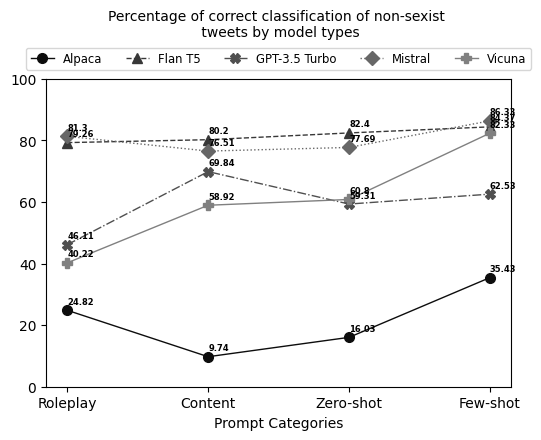

In [365]:
fig, ax = plt.subplots(figsize=(6, 4))

ax.set_xlabel("Prompt Categories") 
ax.set_ylabel("") 
#ax.set_title("Percentage of correct classification of non-sexist \n tweets by model types", fontdict={'fontsize': 10}) 

# Individually plot lines in solid, dotted, dashed and dashdot

line1, = ax.plot(list_models, score_table_0['Alpaca'], linestyle='-', color='#0d0d0d', marker='o', linewidth=1, markersize=7, label='Alpaca') # Default line style
line2, = ax.plot(list_models, score_table_0['Flan-T5'], linestyle='--', color='#383838', marker='^', linewidth=1, markersize=7, label='Flan T5')
line3, = ax.plot(list_models, score_table_0['GPT'], linestyle='-.', color='#4f4f4f', marker='X', linewidth=1, markersize=7, label='GPT-3.5 Turbo')
line4, = ax.plot(list_models, score_table_0['Mistral'], linestyle=':', color='#676767', marker='D', linewidth=1, markersize=7, label='Mistral')
line5, = ax.plot(list_models, score_table_0['Vicuna'], linestyle='-', color='#808080', marker='P', linewidth=1, markersize=7, label='Vicuna') 

palette = ['#0d0d0d', '#383838', '#4f4f4f', '#676767', '#808080']

for item, color in zip(score_table_0.groupby('prompt type'), palette):
    #print(item[0])
    #print(item[1])
    for a,b,c,d,e in item[1][['Alpaca', 'Flan-T5', 'GPT', 'Mistral', 'Vicuna']].values:
        #print(a,b,c,d,item[0])
        plt.text(item[0], a + 2, a, fontsize = 6, weight="bold")
        plt.text(item[0], b + 2, b, fontsize = 6, weight="bold")
        plt.text(item[0], c + 2, c, fontsize = 6, weight="bold")
        plt.text(item[0], d + 2, d, fontsize = 6, weight="bold")
        plt.text(item[0], e + 2, e, fontsize = 6, weight="bold")


# Show the plot
plt.ylim([0, 100])
plt.legend(loc="upper center", handles=[line1, line2, line3, line4, line5], fontsize='small', bbox_to_anchor=(0.5, 1.12), ncol = len(ax.lines)) 
plt.title("Percentage of correct classification of non-sexist \n tweets by model types", fontdict={'fontsize': 10}, x=0.5, y=1.11)
plt.show()

fig.savefig("../images/no-sexism-prompt-model.pdf", bbox_inches='tight')